In [113]:
import numpy as np
import plotly.graph_objects as go
import math
import plotly.io as pio
from scipy.special import softmax
pio.renderers.default = "png"

# Short-corrdior gridworld

## REINFORCE

In [114]:
def sampleSCGTrajectory(theta, nIterMax=1000):
    probs = softmax(theta)

    stateTrajectory = []
    actionTrajectory = []
    rewardTrajectory = []

    currentState = 0
    iter = 0
    while iter < nIterMax:
        currentAction = np.random.choice([1, -1], p=probs)
        currentReward = -1
        stateTrajectory.append(currentState)
        actionTrajectory.append(currentAction)
        rewardTrajectory.append(currentReward)

        if currentState == 1:
            nextState = currentState - currentAction
        else:
            nextState = max(0, currentState + currentAction)

        if nextState == 3:
            break

        currentState = nextState
        iter += 1

    trajectory = np.empty((len(stateTrajectory), 3), dtype=int)
    trajectory[:, 0] = stateTrajectory
    trajectory[:, 1] = actionTrajectory
    trajectory[:, 2] = rewardTrajectory

    return trajectory

In [115]:
def REINFORCE(nEpisodes, thetaInit, alpha, nIterMax=1000):
    theta = thetaInit.copy()
    totalRewards = np.empty(nEpisodes)

    for episode in range(nEpisodes):
        trajectory = sampleSCGTrajectory(theta, nIterMax=nIterMax)
        T = len(trajectory)
        totalRewards[episode] = -T
        for t in range(T):
            gain = - (T - t)
            probs = softmax(theta)
            if trajectory[t, 1] == -1:
                gradient = probs[0] * np.array([-1.0, 1.0])
                
            else:
                gradient = probs[1] * np.array([1.0, -1.0])

            theta += alpha * gain * gradient
        
    return totalRewards

In [116]:
alphasSCG = [2**(-12), 2**(-13), 2**(-14)]
nRepsSCG = 100
nEpisodesSCG = 1000
thetaInitSCG = np.array([0.0, np.log(19)])

totalRewardAvgSCG = []
for alpha in alphasSCG:
    print(alpha)
    totalRewardAlpha = []
    for rep in range(nRepsSCG):
        totalReward = REINFORCE(nEpisodesSCG, thetaInitSCG, alpha, nIterMax=100)
        totalRewardAlpha.append(totalReward)

    totalRewardAvgSCG.append(np.mean(totalRewardAlpha, axis=0))

0.000244140625
0.0001220703125
6.103515625e-05


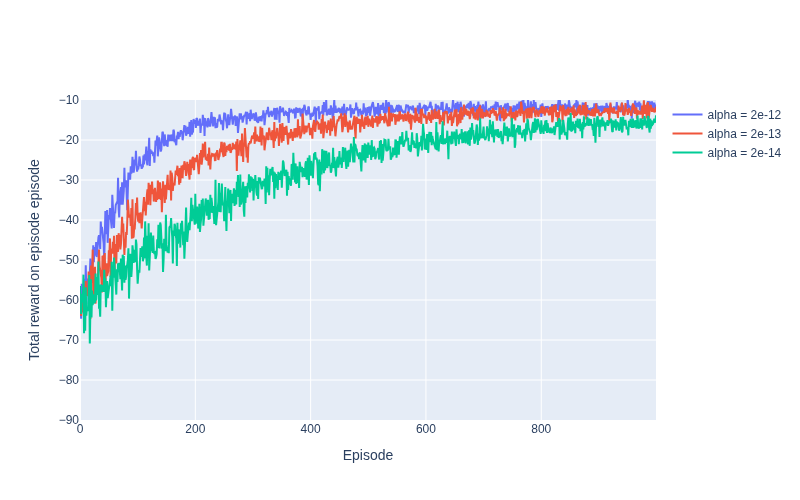

In [117]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=totalRewardAvgSCG[0], name="alpha = 2e-12"))
fig.add_trace(go.Scatter(y=totalRewardAvgSCG[1], name="alpha = 2e-13"))
fig.add_trace(go.Scatter(y=totalRewardAvgSCG[2], name="alpha = 2e-14"))
fig.update_yaxes(range=[-90, -10])
fig.update_layout(xaxis_title="Episode", yaxis_title="Total reward on episode episode", width=800)

## REINFORCE with Baseline

In [121]:
def REINFORCEwithBaseline(nEpisodes, thetaInit, wInit, alphaTheta, alphaW, nIterMax=1000):
    theta = thetaInit.copy()
    W = wInit
    totalRewards = np.empty(nEpisodes)

    for episode in range(nEpisodes):
        trajectory = sampleSCGTrajectory(theta, nIterMax=nIterMax)
        T = len(trajectory)
        totalRewards[episode] = -T
        for t in range(T):
            gain = - (T - t)
            probs = softmax(theta)
            delta = gain - W
            W += alphaW * delta
            if trajectory[t, 1] == -1:
                gradient = probs[0] * np.array([-1.0, 1.0])
                
            else:
                gradient = probs[1] * np.array([1.0, -1.0])

            theta += alphaTheta * delta * gradient
        
    return totalRewards

In [ ]:
alphaThetaSCG = 2**(-9)
alphaWSCG = 2**(-6)
alphaSCG = 2**(-13)

nEpisodesSCG = 1000
nRepsSCG = 100
thetaInitSCG = np.array([0.0, np.log(19)])
wInitSCG = 0

totalRewardAvgSCG = []
totalRewardAvgSCGBaseline = []
for rep in range(nRepsSCG):
    totalRewardAvgSCG.append(REINFORCE(nEpisodesSCG, thetaInitSCG, alphaSCG))
    totalRewardAvgSCGBaseline.append(REINFORCEwithBaseline(nEpisodesSCG, thetaInitSCG, wInitSCG, alphaThetaSCG, alphaWSCG))

totalRewardAvgSCG = np.mean(totalRewardAvgSCG, axis=0)
totalRewardAvgSCGBaseline = np.mean(totalRewardAvgSCGBaseline, axis=0)

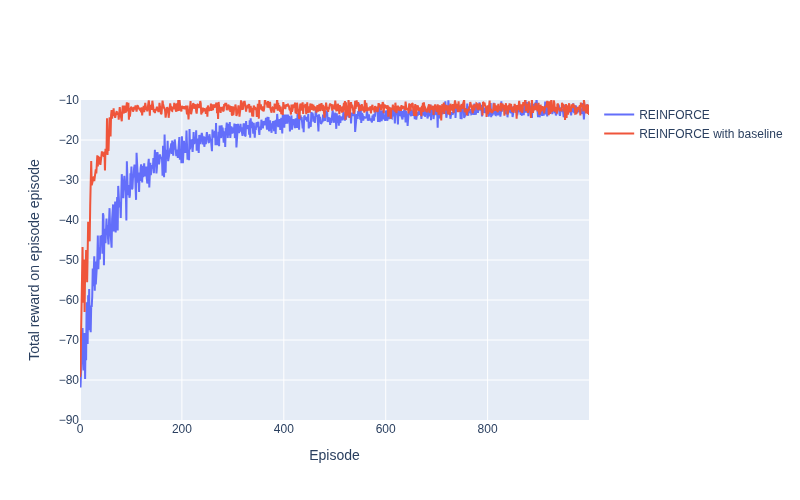

In [123]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=totalRewardAvgSCG, name="REINFORCE"))
fig.add_trace(go.Scatter(y=totalRewardAvgSCGBaseline, name="REINFORCE with baseline"))
fig.update_yaxes(range=[-90, -10])
fig.update_layout(xaxis_title="Episode", yaxis_title="Total reward on episode episode", width=800)